# Escalonamento Multidimensional (ESM)
## Distâncias geográficas entre cidades (superfície da Terra)

**Objetivo:** a partir apenas da matriz de distâncias (km) entre 18 cidades, reconstruir as posições das cidades em um espaço de dimensão reduzida ($q = 2$ ou $3$) e avaliar a qualidade da reconstrução.

É o *problema inverso* de um mapa: em vez de medir distâncias a partir de localizações, **recuperamos localizações a partir de distâncias** (a menos de rotações e reflexões).

**Roteiro**
1. Leitura dos dados
2. A superfície da Terra não é euclidiana (Pitágoras e desigualdade triangular)
3. ESM clássico passo a passo (dupla centralização + decomposição espectral)
4. Autovalores e medidas de distorção
5. Resultados com $q=2$ e $q=3$
6. Comentários

## 0. Pacotes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

np.set_printoptions(suppress=True, precision=4)

## 1. Leitura dos dados

O arquivo `atlas_dist.csv` contém apenas o **triângulo inferior** da matriz de distâncias (em km). Precisamos:
- completar o triângulo superior (a matriz é simétrica);
- colocar zeros na diagonal.

Estas são as propriedades 1 e 2 de uma matriz de dissimilaridade $D$ (slide 7).

In [2]:
# No Colab, execute esta célula para enviar o arquivo atlas_dist.csv.
# Localmente (VS Code), basta o arquivo estar na mesma pasta do notebook.
import os
if not os.path.exists("atlas_dist.csv"):
    from google.colab import files
    files.upload()

In [3]:
raw = pd.read_csv("atlas_dist.csv", index_col=0)

# O arquivo tem 17 linhas (Cape Town ... Tokyo) e 17 colunas (Beijing ... Stockholm).
# Reindexamos para uma matriz 18 x 18 com todas as cidades.
cidades = list(raw.columns) + [raw.index[-1]]
raw = raw.reindex(index=cidades, columns=cidades)

# Triângulo inferior -> matriz simétrica com diagonal nula
A = raw.to_numpy(dtype=float)
A = np.nan_to_num(A, nan=0.0)
D = A + A.T
np.fill_diagonal(D, 0.0)

D = pd.DataFrame(D, index=cidades, columns=cidades)
n = len(cidades)
print(f"{n} cidades")
D.iloc[:5, :5]   # mesma amostra do slide 19

18 cidades


,Beijing,Cape Town,Hong Kong,Honolulu,London
Beijing,0.0,12947.0,1972.0,8171.0,8160.0
Cape Town,12947.0,0.0,11867.0,18562.0,9635.0
Hong Kong,1972.0,11867.0,0.0,8945.0,9646.0
Honolulu,8171.0,18562.0,8945.0,0.0,11653.0
London,8160.0,9635.0,9646.0,11653.0,0.0


In [4]:
# Verificações das propriedades de D
M = D.to_numpy()
print("Diagonal nula:      ", np.all(np.diag(M) == 0))
print("Simétrica:          ", np.allclose(M, M.T))
print("Elementos >= 0:     ", np.all(M >= 0))

Diagonal nula:       True
Simétrica:           True
Elementos >= 0:      True


## 2. A Terra não é euclidiana

A superfície da Terra é apenas **localmente** euclidiana. As distâncias do atlas são medidas ao longo da superfície (círculo máximo), e não em linha reta. Consequência: o teorema de Pitágoras **não** vale, mas a **desigualdade triangular** ($\delta_{ij} \le \delta_{ik} + \delta_{kj}$) continua valendo, o que garante uma distância *métrica* (slide 7).

Exemplo com Beijing, Cape Town e Rio de Janeiro (slides 20–21).

In [5]:
tri = ["Beijing", "Cape Town", "Rio de Janeiro"]
Delta = D.loc[tri, tri] ** 2     # distâncias ao quadrado
print(Delta.astype(int))

                  Beijing  Cape Town  Rio de Janeiro
Beijing                 0  167624809       300155625
Cape Town       167624809          0        36905625
Rio de Janeiro  300155625   36905625               0


In [6]:
d_BR = D.loc["Beijing", "Rio de Janeiro"]
d_BC = D.loc["Beijing", "Cape Town"]
d_CR = D.loc["Cape Town", "Rio de Janeiro"]

print("Pitágoras:  d(B,R)^2 == d(B,C)^2 + d(C,R)^2 ?", d_BR**2 == d_BC**2 + d_CR**2)
print(f"   {d_BR**2:,.0f}  vs  {d_BC**2 + d_CR**2:,.0f}")
print()
print("Desigualdade triangular:  d(B,R) < d(B,C) + d(C,R) ?", d_BR < d_BC + d_CR)
print(f"   {d_BR:,.0f}  vs  {d_BC + d_CR:,.0f}")

Pitágoras:  d(B,R)^2 == d(B,C)^2 + d(C,R)^2 ? False
   300,155,625  vs  204,530,434

Desigualdade triangular:  d(B,R) < d(B,C) + d(C,R) ? True
   17,325  vs  19,022


In [7]:
# A desigualdade triangular vale para TODAS as trincas de cidades?
violacoes = [(i, j, k) for i, j, k in combinations(range(n), 3)
             if (M[i, j] > M[i, k] + M[k, j] + 1e-9) or
                (M[i, k] > M[i, j] + M[j, k] + 1e-9) or
                (M[j, k] > M[j, i] + M[i, k] + 1e-9)]
print(f"Trincas testadas: {len(list(combinations(range(n), 3)))}")
print(f"Violações da desigualdade triangular: {len(violacoes)}")
for i, j, k in violacoes:
    print("  ->", cidades[i], cidades[j], cidades[k])

Trincas testadas: 816
Violações da desigualdade triangular: 1
  -> Moscow Rome Tokyo


**Nota:** a (única) violação detectada, de apenas 1 km (Rome–Tokyo = 9881 contra Rome–Moscow + Moscow–Tokyo = 9880), é consequência do **arredondamento** das distâncias para km inteiros; na prática, a desigualdade triangular vale.

## 3. ESM clássico passo a passo

Seja $\delta_{ij}$ a distância entre as cidades $i$ e $j$. Se as distâncias fossem euclidianas, com $B = XX^\top$ (colunas de $X$ centradas), teríamos
$$\delta_{ij}^2 = b_{ii} + b_{jj} - 2 b_{ij}.$$

Invertendo essa relação (slides 9–12):
$$B = -\tfrac{1}{2}\, H\, D^{*}\, H, \qquad H = I - \tfrac{1}{n}\mathbf{1}\mathbf{1}^\top,$$
em que $D^{*}$ tem entradas $\delta_{ij}^2$.

Depois, com a decomposição espectral $B = Q \Lambda Q^\top$, as coordenadas em $\mathbb{R}^q$ são
$$Y_{n\times q} = Q_q\, \Lambda_q^{1/2},$$
usando os $q$ maiores autovalores (teorema de Eckart–Young–Mirsky).

In [8]:
# Passo 1: matriz de distâncias ao quadrado
Dstar = M ** 2

# Passo 2: matriz de centralização H = I - (1/n) 11'
H = np.eye(n) - np.ones((n, n)) / n

# Passo 3: dupla centralização  B = -1/2 H D* H
B = -0.5 * H @ Dstar @ H

print("B é simétrica:", np.allclose(B, B.T))
print("Linhas de B somam zero:", np.allclose(B.sum(axis=1), 0, atol=1e-4 * np.abs(B).max() * 1e-3))

B é simétrica: True
Linhas de B somam zero: True


In [9]:
# Passo 4: decomposição espectral de B (eigh: matriz simétrica)
autovalores, autovetores = np.linalg.eigh(B)

# eigh devolve em ordem crescente; ordenamos do maior para o menor
ordem = np.argsort(autovalores)[::-1]
lam = autovalores[ordem]
Q = autovetores[:, ordem]

def esm_classico(q):
    """Coordenadas Y = Q_q * Lambda_q^{1/2} (usa apenas autovalores positivos)."""
    return Q[:, :q] * np.sqrt(lam[:q])

## 4. Autovalores e distorção

Se as distâncias fossem euclidianas, $B$ seria semidefinida positiva (todos os autovalores $\ge 0$). Aqui, como a Terra é curva, **aparecem autovalores negativos**.

In [10]:
tabela = pd.DataFrame({
    "autovalor": lam,
    "|autovalor| / soma |autovalores|": np.abs(lam) / np.abs(lam).sum(),
}, index=[f"λ{i+1}" for i in range(n)])
tabela["acumulado"] = tabela.iloc[:, 1].cumsum()
print("Autovalores negativos:", np.sum(lam < -1e-8))
tabela.round(4)

Autovalores negativos: 8


,autovalor,|autovalor| / soma |autovalores|,acumulado
λ1,4.715825e+08,0.3599,0.3599
λ2,3.168248e+08,0.2418,0.6017
λ3,2.539437e+08,0.1938,0.7955
λ4,3.173635e+07,0.0242,0.8197
λ5,4.338497e+06,0.0033,0.8230
λ6,1.747583e+06,0.0013,0.8243
λ7,1.451132e+05,0.0001,0.8244
λ8,6.047711e+04,0.0000,0.8245
λ9,1.001756e+02,0.0000,0.8245
λ10,0.000000e+00,0.0000,0.8245


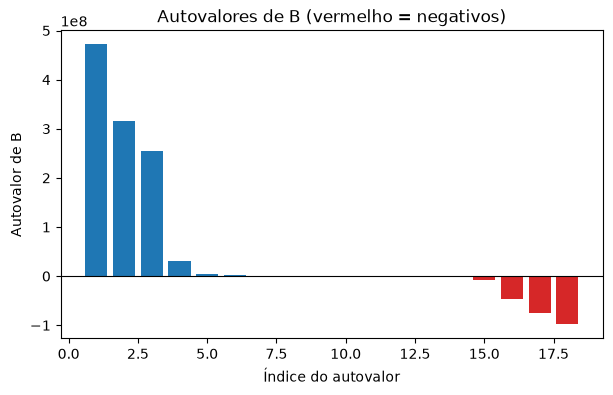

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, n + 1), lam, color=np.where(lam >= 0, "tab:blue", "tab:red"))
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Índice do autovalor")
ax.set_ylabel("Autovalor de B")
ax.set_title("Autovalores de B (vermelho = negativos)")
plt.show()

### Medidas de distorção

- **Proporção de variabilidade (heurística do curso):**
$\displaystyle \text{distor}(q) = \frac{\sum_{k=1}^{q} |\lambda_k|}{\sum_{k=1}^{n} |\lambda_k|}$ — quanto mais perto de 1, melhor; regra prática: $> 0{,}70$.
- **Mardia et al. (1979):** $P = \sum_{k=1}^{q}\lambda_k^2 \big/ \sum_{k=1}^{p}\lambda_k^2$ — quanto mais perto de 1, melhor.
- **Stress de Kruskal (1964):** $\sqrt{\sum_{i<j}(\delta_{ij}-d_{ij}^{(m)})^2 \big/ \sum_{i<j}\delta_{ij}^2}$ — quanto mais perto de 0, melhor.

In [12]:
def distor(q):
    return np.abs(lam[:q]).sum() / np.abs(lam).sum()

def mardia(q):
    return (lam[:q] ** 2).sum() / (lam ** 2).sum()

def dist_euclid(Y):
    diff = Y[:, None, :] - Y[None, :, :]
    return np.sqrt((diff ** 2).sum(axis=-1))

def stress_kruskal(Y):
    d = dist_euclid(Y)
    iu = np.triu_indices(n, k=1)
    return np.sqrt(((M[iu] - d[iu]) ** 2).sum() / (M[iu] ** 2).sum())

resumo = pd.DataFrame({
    "distor": [distor(q) for q in (2, 3)],
    "Mardia (P)": [mardia(q) for q in (2, 3)],
    "Stress (Kruskal)": [stress_kruskal(esm_classico(q)) for q in (2, 3)],
}, index=["q = 2", "q = 3"])
resumo.round(4)

,distor,Mardia (P),Stress (Kruskal)
q = 2,0.6017,0.7952,0.1857
q = 3,0.7955,0.9540,0.1438


## 5. Resultados

### 5.1 ESM com $q = 2$

In [13]:
Y2 = esm_classico(2)
pts2 = pd.DataFrame(Y2, index=cidades, columns=["y1", "y2"])
print(f"distor (q=2) = {distor(2):.7f} ")

distor (q=2) = 0.6016631 


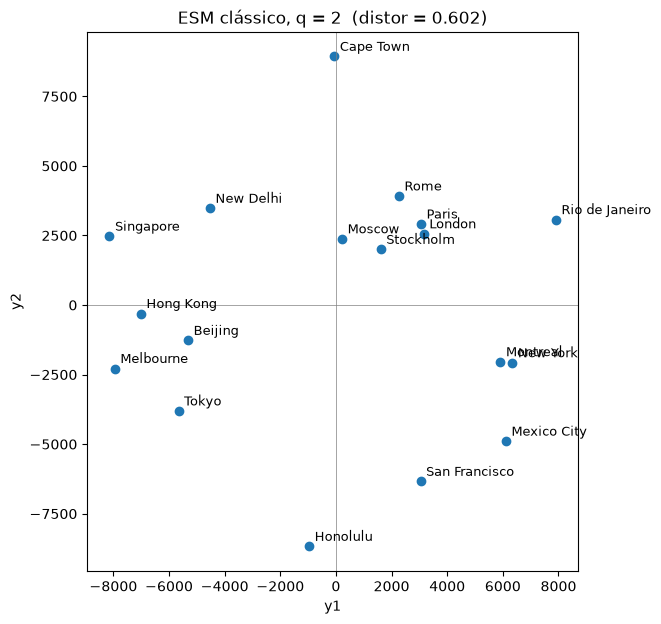

In [14]:
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(pts2.y1, pts2.y2, color="tab:blue")
for nome, (x, y) in pts2.iterrows():
    ax.annotate(nome, (x, y), textcoords="offset points", xytext=(4, 4), fontsize=9)
ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
ax.set_xlabel("y1"); ax.set_ylabel("y2")
ax.set_title(f"ESM clássico, q = 2  (distor = {distor(2):.3f})")
ax.set_aspect("equal")
plt.show()

**Atenção à interpretação:** o ESM só determina as posições *a menos de rotação e reflexão*. Os eixos $y_1, y_2$ **não** são latitude e longitude, e o gráfico pode aparecer girado ou espelhado em relação ao slide 25 (o sinal de cada autovetor é arbitrário). O que importa é a configuração relativa: cidades próximas ficam próximas.

### 5.2 ESM com $q = 3$

In [15]:
Y3 = esm_classico(3)
pts3 = pd.DataFrame(Y3, index=cidades, columns=["y1", "y2", "y3"])
print(f"distor (q=3) = {distor(3):.7f}")

distor (q=3) = 0.7954570


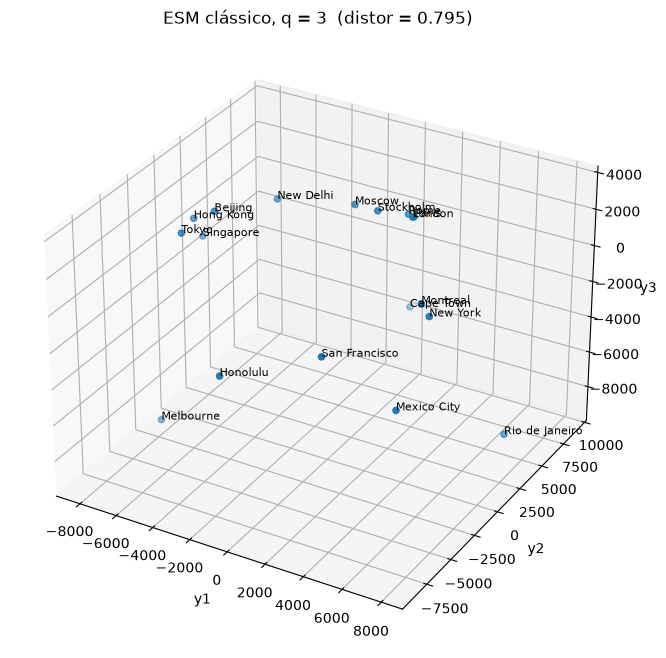

In [16]:
%matplotlib inline
fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(projection="3d")
ax.scatter(pts3.y1, pts3.y2, pts3.y3, color="tab:blue")
for nome, (x, y, z) in pts3.iterrows():
    ax.text(x, y, z, nome, fontsize=8)
ax.set_xlabel("y1"); ax.set_ylabel("y2"); ax.set_zlabel("y3")
ax.set_title(f"ESM clássico, q = 3  (distor = {distor(3):.3f})")
plt.show()

### 5.3 Conferência

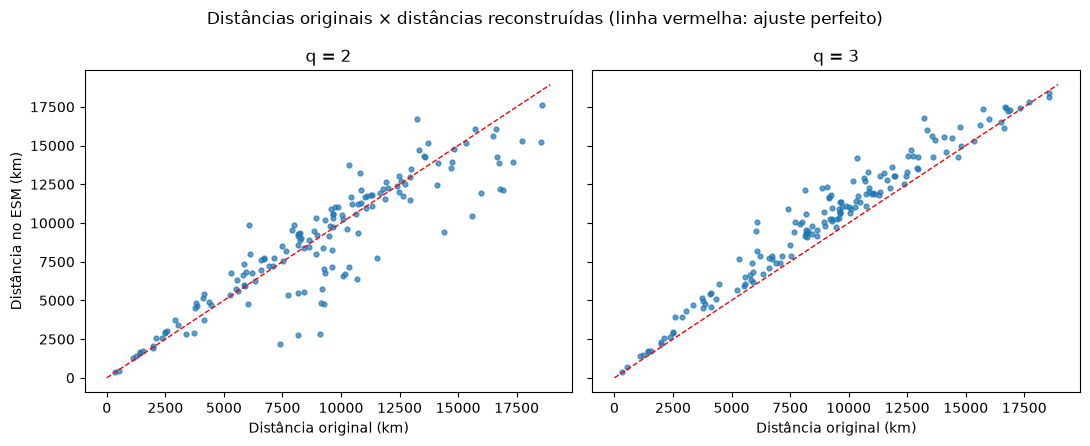

In [17]:
# As distâncias reconstruídas aproximam as originais?
d2 = dist_euclid(Y2); d3 = dist_euclid(Y3)
iu = np.triu_indices(n, k=1)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, d, q in zip(axs, (d2, d3), (2, 3)):
    ax.scatter(M[iu], d[iu], s=12, alpha=0.7)
    lim = [0, M.max() * 1.02]
    ax.plot(lim, lim, "r--", lw=1)
    ax.set_xlabel("Distância original (km)")
    ax.set_title(f"q = {q}")
axs[0].set_ylabel("Distância no ESM (km)")
plt.suptitle("Distâncias originais × distâncias reconstruídas (linha vermelha: ajuste perfeito)")
plt.tight_layout()
plt.show()

## 6. Comentários

- Com a heurística $\text{distor} > 0{,}70$, **apenas $q=3$** ($\approx 0{,}80$) é satisfatório; com $q=2$ ($\approx 0{,}60$) obtém-se, ainda assim, uma aproximação bem razoável das distâncias entre as cidades.
- A distorção não chega a 1 porque as distâncias sobre a superfície terrestre **não são euclidianas** (há autovalores negativos em $B$). Em 3D, a configuração se aproxima de uma esfera.
- Para dados **não métricos** (por exemplo, distâncias sobre a superfície) existem extensões, baseadas na ordenação das distâncias: ESM não métrico (Kruskal), mapeamento de Sammon e diagramas de Shepard. No R: `MASS::isoMDS`, `MASS::sammon`, `MASS::Shepard`.